# Session 14: Types of Machine Learning in Python

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q'] + ['flask', 'requests', 'beautifulsoup4', 'lxml', 'scikit-learn', 'seaborn'], check=False)
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/04-application-based-programming-in-python/code/'
    for f in []:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or '.', exist_ok=True)
            subprocess.run(['wget', '-q', '-O', f, base + f], check=False)
print('ready')

ready


## Example: `session-14_logistic_regression.py`

In [2]:
"""
Session 14 · Example 1: supervised learning - logistic regression for classification
------------------------------------------------------------------------------------
Question: from hours studied, can we predict whether a student passes?
Logistic regression outputs a PROBABILITY with the sigmoid function
    p = 1 / (1 + e^-(b0 + b1*x))
and predicts "pass" when p >= 0.5.
Run:  python session-14_logistic_regression.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, classification_report
from sklearn.model_selection import train_test_split

def sigmoid(z):
    return 1 / (1 + np.exp(-z))
print("sigmoid squashes any number into (0, 1):", {z: round(float(sigmoid(z)), 3) for z in (-6, -2, 0, 2, 6)})

rng = np.random.default_rng(14)
hours = rng.uniform(0, 12, 200).round(1)
passed = (rng.random(200) < sigmoid(1.1 * (hours - 5.5))).astype(int)      # the hidden 'true' rule
X = hours.reshape(-1, 1)                                                   # scikit-learn wants a 2-D X
X_train, X_test, y_train, y_test = train_test_split(X, passed, test_size=0.25, random_state=0, stratify=passed)

model = LogisticRegression()
model.fit(X_train, y_train)                                                # learn b0 and b1
b0, b1 = model.intercept_[0], model.coef_[0, 0]
print(f"\nlearned: b0 = {b0:.2f}, b1 = {b1:.2f}  -> 50 % chance at {-b0 / b1:.1f} hours")
print(f"each extra hour multiplies the odds of passing by e^b1 = {np.exp(b1):.2f}")

for h in [2, 5, 6, 9]:
    p = model.predict_proba([[h]])[0, 1]
    print(f"  {h:>2} hours -> P(pass) = {p:.2f} -> predict {'pass' if p >= 0.5 else 'fail'}")

pred = model.predict(X_test)
print("\naccuracy :", round(accuracy_score(y_test, pred), 3))
print("precision:", round(precision_score(y_test, pred), 3), "(of predicted passes, how many really passed)")
print("recall   :", round(recall_score(y_test, pred), 3), "(of real passes, how many we caught)")
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
print(f"confusion matrix: TN={tn} FP={fp} FN={fn} TP={tp}")
print(classification_report(y_test, pred, target_names=["fail", "pass"]))

xs = np.linspace(0, 12, 200).reshape(-1, 1)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(hours, passed + rng.normal(0, 0.02, 200), s=12, alpha=0.5, color="#A78BFA", label="students (0 = fail, 1 = pass)")
ax.plot(xs, model.predict_proba(xs)[:, 1], color="#FF6B1A", lw=2.5, label="P(pass) from the model")
ax.axhline(0.5, color="gray", ls=":"); ax.axvline(-b0 / b1, color="#F43F5E", ls="--", label="decision boundary")
ax.set_xlabel("hours studied per week"); ax.set_ylabel("probability of passing"); ax.legend(fontsize=8)
ax.set_title("Logistic regression turns a score into a probability")
fig.tight_layout(); fig.savefig("session-14_logistic_regression.png", dpi=100)
print("Saved session-14_logistic_regression.png")

sigmoid squashes any number into (0, 1): {-6: 0.002, -2: 0.119, 0: 0.5, 2: 0.881, 6: 0.998}

learned: b0 = -7.89, b1 = 1.38  -> 50 % chance at 5.7 hours
each extra hour multiplies the odds of passing by e^b1 = 3.97
   2 hours -> P(pass) = 0.01 -> predict fail
   5 hours -> P(pass) = 0.27 -> predict fail
   6 hours -> P(pass) = 0.59 -> predict pass
   9 hours -> P(pass) = 0.99 -> predict pass

accuracy : 0.96
precision: 1.0 (of predicted passes, how many really passed)
recall   : 0.923 (of real passes, how many we caught)
confusion matrix: TN=24 FP=0 FN=2 TP=24
              precision    recall  f1-score   support

        fail       0.92      1.00      0.96        24
        pass       1.00      0.92      0.96        26

    accuracy                           0.96        50
   macro avg       0.96      0.96      0.96        50
weighted avg       0.96      0.96      0.96        50

Saved session-14_logistic_regression.png


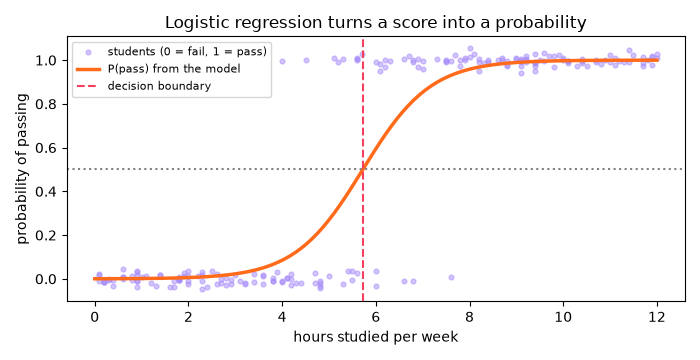

In [3]:
from IPython.display import Image, display
display(Image(filename='session-14_logistic_regression.png'))  # chart saved by the cell above

## Example: `session-14_kmeans.py`

In [4]:
"""
Session 14 · Example 2: unsupervised learning - k-means clustering
------------------------------------------------------------------
No labels: the algorithm groups similar points by itself.
  1. pick k starting centres     2. assign each point to its nearest centre
  3. move each centre to the mean of its points     4. repeat until nothing changes
We implement it from scratch, compare with scikit-learn, and choose k with the
elbow method and the silhouette score.
Run:  python session-14_kmeans.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

X, true_groups = make_blobs(n_samples=300, centers=[[2, 2], [8, 3], [5, 8]], cluster_std=1.1, random_state=4)

def kmeans_scratch(X, k, iters=20, seed=0, verbose=True):
    rng = np.random.default_rng(seed)
    centres = X[rng.choice(len(X), k, replace=False)]                 # step 1
    for it in range(1, iters + 1):
        dists = np.linalg.norm(X[:, None, :] - centres[None, :, :], axis=2)
        labels = dists.argmin(axis=1)                                 # step 2
        new = np.array([X[labels == j].mean(axis=0) for j in range(k)])   # step 3
        moved = np.linalg.norm(new - centres)
        centres = new
        if verbose:
            print(f"  iteration {it}: centres moved {moved:.3f}")
        if moved < 1e-6:                                              # step 4: converged
            break
    inertia = ((X - centres[labels]) ** 2).sum()
    return labels, centres, inertia

print("From scratch (k = 3):")
labels, centres, inertia = kmeans_scratch(X, 3)
print("centres:", np.round(centres[np.argsort(centres[:, 0])], 2).tolist(), "| inertia:", round(inertia, 1))
print("-> stuck in a poor local optimum: two centres started in the same blob.")
runs = [kmeans_scratch(X, 3, seed=s, verbose=False) for s in range(10)]      # restart 10 times
labels, centres, inertia = min(runs, key=lambda r: r[2])                      # keep the best
print("best of 10 random starts -> inertia", round(inertia, 1), "| inertias seen:",
      sorted({round(float(r[2]), 1) for r in runs}))

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
print("\nscikit-learn centres:", np.round(km.cluster_centers_[np.argsort(km.cluster_centers_[:, 0])], 2).tolist(),
      "| inertia:", round(km.inertia_, 1))
print("new points ->", km.predict([[1, 1], [9, 2], [5, 9]]).tolist())

print("\nChoosing k:")
ks, inertias, sils = range(1, 9), [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(X, m.labels_) if k > 1 else np.nan)
    print(f"  k={k}: inertia {m.inertia_:8.1f}" + (f"  silhouette {sils[-1]:.3f}" if k > 1 else ""))
best_k = int(np.nanargmax(sils)) + 1
print("best k by silhouette:", best_k)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].scatter(X[:, 0], X[:, 1], s=10, color="#6B7280"); ax[0].set_title("What k-means sees: no labels")
ax[1].scatter(X[:, 0], X[:, 1], c=km.labels_, cmap="plasma", s=10)
ax[1].scatter(*km.cluster_centers_.T, marker="X", s=200, color="black"); ax[1].set_title("k-means result (X = centres)")
ax[2].plot(list(ks), inertias, "o-", color="#FF6B1A"); ax[2].set_xlabel("k"); ax[2].set_ylabel("inertia")
ax2 = ax[2].twinx(); ax2.plot(list(ks), sils, "s--", color="#A78BFA"); ax2.set_ylabel("silhouette", color="#A78BFA")
ax[2].set_title("Elbow (inertia) and silhouette")
fig.tight_layout(); fig.savefig("session-14_kmeans.png", dpi=95)
print("Saved session-14_kmeans.png")

From scratch (k = 3):
  iteration 1: centres moved 3.074
  iteration 2: centres moved 0.535
  iteration 3: centres moved 0.000
centres: [[2.09, 2.69], [2.19, 1.09], [6.63, 5.63]] | inertia: 2225.3
-> stuck in a poor local optimum: two centres started in the same blob.
best of 10 random starts -> inertia 668.3 | inertias seen: [668.3, 2225.3]

scikit-learn centres: [[2.14, 1.93], [5.16, 8.04], [8.12, 3.17]] | inertia: 668.3
new points -> [1, 0, 2]

Choosing k:
  k=1: inertia   4547.8
  k=2: inertia   2289.5  silhouette 0.507
  k=3: inertia    668.3  silhouette 0.664
  k=4: inertia    575.8  silhouette 0.543
  k=5: inertia    497.5  silhouette 0.444
  k=6: inertia    415.0  silhouette 0.343
  k=7: inertia    360.2  silhouette 0.364
  k=8: inertia    316.4  silhouette 0.371
best k by silhouette: 3


Saved session-14_kmeans.png


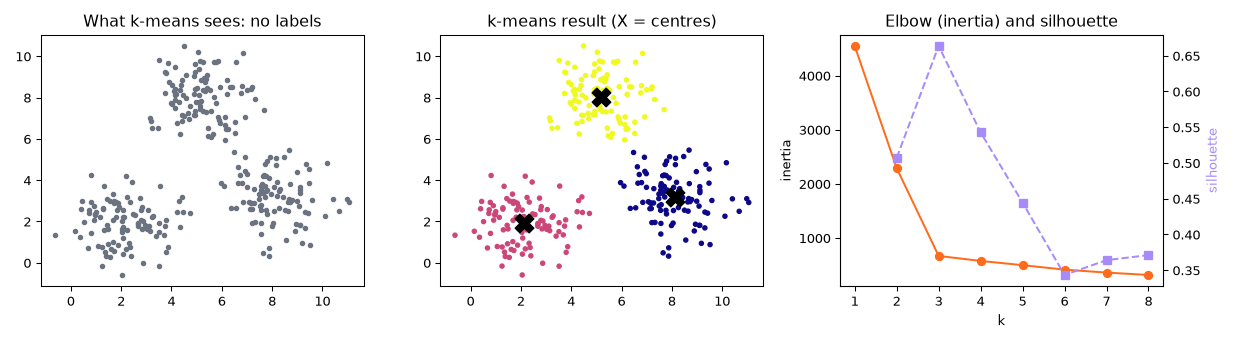

In [5]:
from IPython.display import Image, display
display(Image(filename='session-14_kmeans.png'))  # chart saved by the cell above

## Example: `session-14_reinforcement_learning.py`

In [6]:
"""
Session 14 · Example 3: reinforcement learning - Q-learning in a grid world
---------------------------------------------------------------------------
An agent (a delivery robot) starts at S and must reach the goal G on a 4 x 5
campus map. Walls (#) block movement; a puddle (~) costs -10; every step
costs -1; reaching G gives +20. Nobody tells the robot the route: it learns
from rewards by trial and error, updating a Q-table:
    Q[s, a] <- Q[s, a] + alpha * (reward + gamma * max Q[s', :] - Q[s, a])
Run:  python session-14_reinforcement_learning.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

GRID = ["S..#.",
        ".#.~.",
        ".#...",
        "...#G"]
ROWS, COLS = len(GRID), len(GRID[0])
ACTIONS = {0: (-1, 0, "↑"), 1: (1, 0, "↓"), 2: (0, -1, "←"), 3: (0, 1, "→")}
start = (0, 0)

def step(state, action):
    dr, dc, _ = ACTIONS[action]
    r, c = state[0] + dr, state[1] + dc
    if not (0 <= r < ROWS and 0 <= c < COLS) or GRID[r][c] == "#":
        return state, -2, False                    # bumped into a wall or the edge
    cell = GRID[r][c]
    if cell == "G":
        return (r, c), 20, True
    return (r, c), (-10 if cell == "~" else -1), False

rng = np.random.default_rng(0)
Q = np.zeros((ROWS, COLS, 4))
alpha, gamma, episodes = 0.5, 0.95, 400
returns = []
for ep in range(episodes):
    epsilon = max(0.05, 1 - ep / 250)              # explore a lot first, then exploit
    state, total, done, steps = start, 0, False, 0
    while not done and steps < 100:
        if rng.random() < epsilon:
            action = int(rng.integers(4))           # explore: random action
        else:
            action = int(Q[state].argmax())          # exploit: best known action
        nxt, reward, done = step(state, action)
        Q[state][action] += alpha * (reward + gamma * Q[nxt].max() * (not done) - Q[state][action])
        state, total, steps = nxt, total + reward, steps + 1
    returns.append(total)

print(f"average return, first 50 episodes: {np.mean(returns[:50]):7.1f}")
print(f"average return, last 50 episodes : {np.mean(returns[-50:]):7.1f}")

print("\nLearned policy (best action in each cell):")
for r in range(ROWS):
    print("  " + " ".join(GRID[r][c] if GRID[r][c] in "#G" else ACTIONS[int(Q[r, c].argmax())][2] for c in range(COLS)))

state, path, done = start, [start], False
while not done and len(path) < 20:
    state, _, done = step(state, int(Q[state].argmax()))
    path.append(state)
print("greedy route:", " -> ".join(f"({r},{c})" for r, c in path), f"| {len(path) - 1} steps, puddle avoided:",
      all(GRID[r][c] != "~" for r, c in path))

fig, ax = plt.subplots(figsize=(7, 3.4))
smooth = np.convolve(returns, np.ones(20) / 20, mode="valid")
ax.plot(returns, color="#A78BFA", alpha=0.35, label="return per episode")
ax.plot(range(19, episodes), smooth, color="#FF6B1A", lw=2, label="20-episode average")
ax.set_xlabel("episode"); ax.set_ylabel("total reward"); ax.legend()
ax.set_title("The agent learns from rewards: returns rise as exploration falls")
fig.tight_layout(); fig.savefig("session-14_reinforcement_learning.png", dpi=100)
print("Saved session-14_reinforcement_learning.png")

average return, first 50 episodes:   -81.5
average return, last 50 episodes :    13.2

Learned policy (best action in each cell):
  → → ↓ # ↓
  ↑ # ↓ ↓ ↓
  ↓ # → → ↓
  → → ↑ # G
greedy route: (0,0) -> (0,1) -> (0,2) -> (1,2) -> (2,2) -> (2,3) -> (2,4) -> (3,4) | 7 steps, puddle avoided: True


Saved session-14_reinforcement_learning.png


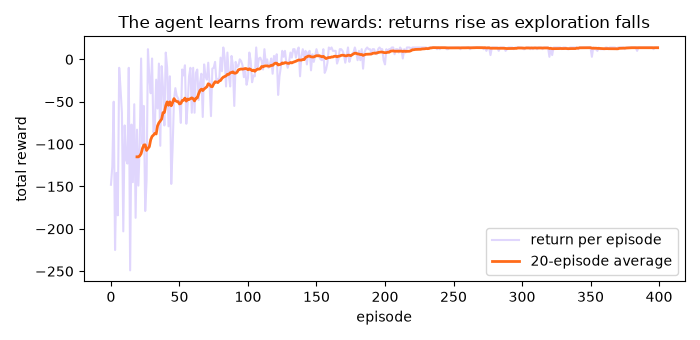

In [7]:
from IPython.display import Image, display
display(Image(filename='session-14_reinforcement_learning.png'))  # chart saved by the cell above

## Example: `session-14_problem_dropout_warning.py`

In [8]:
"""
Session 14 · Real-life problem: an early-warning system for student dropout
---------------------------------------------------------------------------
PROBLEM
A diploma program loses students every term. Using last year's records,
build a SUPERVISED classifier that flags students at risk after week 4, so
advisers can contact them early. Requirements:
  1. features known by week 4 only (attendance, quiz average, assignments
     submitted, commute time, works part-time, fee instalment late),
  2. logistic regression inside a pipeline (scaling), evaluated on a test set,
  3. explain the model with odds ratios that advisers can understand,
  4. pick a probability threshold: missing an at-risk student is worse than
     an extra phone call, so we trade precision for recall,
  5. output a ranked contact list for the new cohort, plus a chart.
Data is synthetic (seeded).
Run:  python session-14_problem_dropout_warning.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(404)
def make_students(n):
    df = pd.DataFrame({
        "attendance_pct": np.clip(rng.normal(80, 12, n), 30, 100).round(0),
        "quiz_avg": np.clip(rng.normal(65, 15, n), 0, 100).round(0),
        "assignments_done": rng.integers(0, 5, n),                 # out of 4 by week 4
        "commute_min": rng.gamma(3, 15, n).round(0),
        "works_part_time": rng.integers(0, 2, n),
        "fee_late": (rng.random(n) < 0.2).astype(int),
    })
    z = (2.0 - 0.07 * (df.attendance_pct - 80) - 0.04 * (df.quiz_avg - 65) - 0.6 * df.assignments_done
         + 0.015 * df.commute_min + 0.7 * df.works_part_time + 1.2 * df.fee_late - 3.1)
    df["dropped_out"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    return df

hist = make_students(900)
features = [c for c in hist.columns if c != "dropped_out"]
print(f"last year: {len(hist)} students, dropout rate {hist.dropped_out.mean():.1%}")
X_tr, X_te, y_tr, y_te = train_test_split(hist[features], hist["dropped_out"], test_size=0.3,
                                          stratify=hist["dropped_out"], random_state=1)
model = make_pipeline(StandardScaler(), LogisticRegression()).fit(X_tr, y_tr)
proba = model.predict_proba(X_te)[:, 1]
print(f"test ROC-AUC: {roc_auc_score(y_te, proba):.3f} (0.5 = guessing, 1.0 = perfect ranking)")

# Explain: refit on unscaled data so each odds ratio is "per 1 unit" of the original feature
plain = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
odds = pd.Series(np.exp(plain.coef_[0]), index=features)
units = {"attendance_pct": "+1 % attendance", "quiz_avg": "+1 quiz mark", "assignments_done": "+1 assignment",
         "commute_min": "+1 min commute", "works_part_time": "has a part-time job", "fee_late": "fee paid late"}
print("\nOdds ratios (how the odds of dropping out change):")
for f, o in odds.sort_values().items():
    print(f"  {units[f]:<22} x{o:5.2f}  ({'lower' if o < 1 else 'higher'} risk)")

print("\nThreshold trade-off on the test set:")
print(f"  {'threshold':>9} {'flagged':>8} {'recall':>7} {'precision':>9}")
rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (proba >= t).astype(int)
    rows.append((t, pred.sum(), recall_score(y_te, pred), precision_score(y_te, pred)))
    print(f"  {t:>9.1f} {pred.sum():>8} {rows[-1][2]:>7.2f} {rows[-1][3]:>9.2f}")
chosen = 0.3
t, flagged, rec, prec = next(r for r in rows if r[0] == chosen)
print(f"chosen threshold {chosen}: catches {rec:.0%} of real dropouts while calling {flagged / len(y_te):.0%} of students")

cohort = make_students(20).drop(columns="dropped_out")
cohort.insert(0, "student", [f"New-{i:02d}" for i in range(1, 21)])
cohort["risk"] = model.predict_proba(cohort[features])[:, 1].round(2)
contact = cohort[cohort["risk"] >= chosen].sort_values("risk", ascending=False)
print(f"\nContact list for the new cohort ({len(contact)} of {len(cohort)} students):")
print(contact[["student", "attendance_pct", "quiz_avg", "assignments_done", "fee_late", "risk"]].to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh([units[f] for f in odds.sort_values().index], odds.sort_values().values,
           color=["#FF6B1A" if o < 1 else "#F43F5E" for o in odds.sort_values().values])
ax[0].axvline(1, color="black", lw=1); ax[0].set_xscale("log"); ax[0].set_title("Odds ratios (log scale; 1 = no effect)")
ts = [r[0] for r in rows]
ax[1].plot(ts, [r[2] for r in rows], "o-", color="#FF6B1A", label="recall")
ax[1].plot(ts, [r[3] for r in rows], "s-", color="#A78BFA", label="precision")
ax[1].invert_xaxis(); ax[1].set_xlabel("probability threshold"); ax[1].legend(); ax[1].set_title("Lower threshold: more caught, more false alarms")
fig.tight_layout(); fig.savefig("session-14_problem_dropout_warning.png", dpi=100)
print("Saved session-14_problem_dropout_warning.png")

last year: 900 students, dropout rate 31.7%
test ROC-AUC: 0.821 (0.5 = guessing, 1.0 = perfect ranking)

Odds ratios (how the odds of dropping out change):
  +1 assignment          x 0.46  (lower risk)
  +1 % attendance        x 0.91  (lower risk)
  +1 quiz mark           x 0.96  (lower risk)
  +1 min commute         x 1.02  (higher risk)
  has a part-time job    x 2.30  (higher risk)
  fee paid late          x 4.42  (higher risk)

Threshold trade-off on the test set:
  threshold  flagged  recall precision
        0.5       73    0.55      0.64


        0.4       85    0.62      0.62
        0.3      109    0.73      0.58
        0.2      141    0.87      0.53
chosen threshold 0.3: catches 73% of real dropouts while calling 40% of students

Contact list for the new cohort (5 of 20 students):
student  attendance_pct  quiz_avg  assignments_done  fee_late  risk
 New-14            74.0      90.0                 0         1  0.90
 New-08            72.0      76.0                 0         1  0.69
 New-09            78.0      71.0                 1         0  0.62
 New-13            80.0      74.0                 0         0  0.57
 New-11            88.0      63.0                 1         0  0.49


Saved session-14_problem_dropout_warning.png


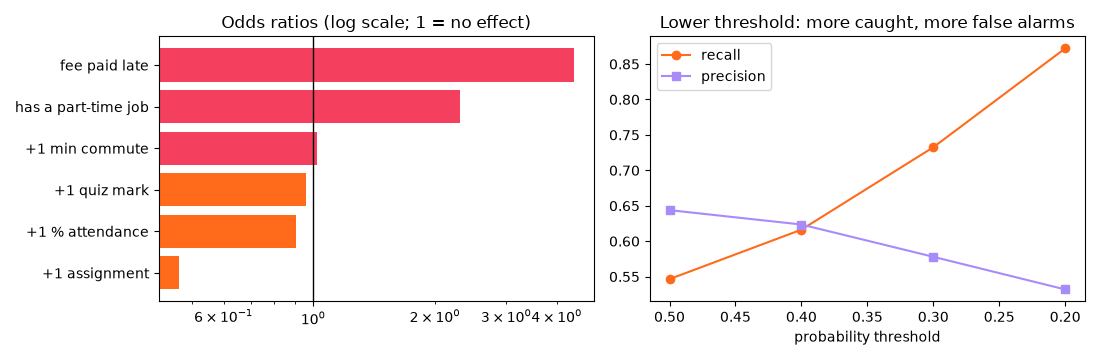

In [9]:
from IPython.display import Image, display
display(Image(filename='session-14_problem_dropout_warning.png'))  # chart saved by the cell above

## Example: `session-14_project_customer_segments.py`

In [10]:
"""
Session 14 · Mini project: customer segmentation for a supermarket (k-means)
---------------------------------------------------------------------------
A supermarket loyalty program has a year of purchase data but no labels.
Using UNSUPERVISED learning we:
  1. build RFM-style features per customer (recency, frequency, spend, basket size),
  2. scale them (k-means uses distances - Session 13),
  3. choose k with the silhouette score,
  4. fit k-means, describe each segment in business language,
  5. suggest one marketing action per segment and plot the segments.
Data is synthetic (seeded) with hidden customer types the algorithm must rediscover.
Run:  python session-14_project_customer_segments.py
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.width", 130)
rng = np.random.default_rng(21)
types = {   # hidden truth: (count, days since last visit, visits/year, avg basket Rs)
    "weekly family": (180, 6, 48, 6500),
    "occasional": (220, 45, 8, 2200),
    "big spender": (60, 12, 30, 15000),
    "lapsed": (140, 160, 3, 1800),
}
rows = []
for t, (cnt, rec, freq, basket) in types.items():
    rows.append(pd.DataFrame({
        "recency_days": np.clip(rng.normal(rec, rec * 0.35, cnt), 1, 365).round(0),
        "visits_per_year": np.clip(rng.normal(freq, freq * 0.3, cnt), 1, None).round(0),
        "avg_basket": np.clip(rng.normal(basket, basket * 0.25, cnt), 300, None).round(-1),
        "hidden_type": t}))
df = pd.concat(rows, ignore_index=True)
df["yearly_spend"] = df["visits_per_year"] * df["avg_basket"]
features = ["recency_days", "visits_per_year", "avg_basket", "yearly_spend"]
print(f"{len(df)} customers, features: {features}")
print(df[features].describe().round(0).loc[["mean", "min", "max"]], "\n")

X = StandardScaler().fit_transform(np.log1p(df[features]))     # log first: spend is very skewed
print("k   inertia   silhouette")
scores = {}
for k in range(2, 8):
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
    scores[k] = silhouette_score(X, m.labels_)
    print(f"{k}   {m.inertia_:7.1f}   {scores[k]:.3f}")
print("silhouette prefers k =", max(scores, key=scores.get), "- a coarse 'active vs inactive' split.")
k = 4
print(f"chosen k = {k}: inertia stops dropping sharply after 4 and four segments give the marketing team")
print("distinct actions. Metrics guide the choice of k; business usefulness decides it.")

km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
df["segment"] = km.labels_
profile = df.groupby("segment")[features].median().round(0)
profile["customers"] = df["segment"].value_counts().sort_index()
profile["share_of_revenue_%"] = (df.groupby("segment")["yearly_spend"].sum() / df["yearly_spend"].sum() * 100).round(1)

def name_segment(r):
    if r.recency_days > 100: return "Lapsed", "win-back SMS with a 15 % voucher"
    if r.avg_basket > 10000: return "VIP big spenders", "personal offers and priority checkout"
    if r.visits_per_year > 30: return "Loyal regulars", "points multiplier on weekly staples"
    return "Occasional shoppers", "bundle deals to bring them in more often"
names = profile.apply(lambda r: pd.Series(name_segment(r), index=["name", "action"]), axis=1)
profile = profile.join(names).sort_values("share_of_revenue_%", ascending=False)
print("\nSegment profiles (medians):\n", profile.drop(columns="action").to_string())
print("\nMarketing plan:")
for _, r in profile.iterrows():  # one line per segment
    print(f"  {r['name']:<20} {int(r['customers']):>4} customers, {r['share_of_revenue_%']:>5}% of revenue -> {r['action']}")

check = pd.crosstab(df["hidden_type"], df["segment"].map(profile["name"]))
print("\nHow well did k-means rediscover the hidden types? (rows = truth)\n", check)
purity = check.max(axis=1).sum() / len(df)
print(f"purity: {purity:.1%} of customers sit in the segment matching their hidden type")

pts = PCA(n_components=2).fit_transform(X)                       # squash 4-D to 2-D for plotting
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colours = ["#FF6B1A", "#A78BFA", "#F43F5E", "#FCD34D", "#6B7280", "#22C55E", "#0EA5E9"]
for seg in profile.index:
    m = df["segment"] == seg
    ax[0].scatter(pts[m, 0], pts[m, 1], s=10, color=colours[seg], label=profile.loc[seg, "name"])
ax[0].set_title("Segments (PCA projection of 4 features)"); ax[0].legend(fontsize=8)
ax[1].bar(profile["name"], profile["share_of_revenue_%"], color=[colours[s] for s in profile.index])
ax[1].set_ylabel("% of yearly revenue"); ax[1].set_title("Who brings in the money?"); ax[1].tick_params(axis="x", rotation=15)
fig.tight_layout(); fig.savefig("session-14_project_customer_segments.png", dpi=95)
print("Saved session-14_project_customer_segments.png")

600 customers, features: ['recency_days', 'visits_per_year', 'avg_basket', 'yearly_spend']
      recency_days  visits_per_year  avg_basket  yearly_spend
mean          56.0             21.0      4739.0      148476.0
min            1.0              1.0       690.0        1550.0
max          264.0             81.0     23500.0      730210.0 

k   inertia   silhouette
2     443.9   0.708
3     274.2   0.585
4     199.3   0.506
5     175.5   0.472
6     155.1   0.380


7     142.1   0.347
silhouette prefers k = 2 - a coarse 'active vs inactive' split.
chosen k = 4: inertia stops dropping sharply after 4 and four segments give the marketing team
distinct actions. Metrics guide the choice of k; business usefulness decides it.

Segment profiles (medians):
          recency_days  visits_per_year  avg_basket  yearly_spend  customers  share_of_revenue_%                 name
segment                                                                                                             
1                 6.0             48.0      6795.0      320180.0        178                64.7       Loyal regulars
3                12.0             29.0     15470.0      448500.0         61                30.0     VIP big spenders
2                45.0              8.0      2160.0       17550.0        219                 4.4  Occasional shoppers
0               158.0              3.0      1810.0        5515.0        142                 0.9               Lapsed

Marketi


How well did k-means rediscover the hidden types? (rows = truth)
 segment        Lapsed  Loyal regulars  Occasional shoppers  VIP big spenders
hidden_type                                                                 
big spender         0               2                    0                58
lapsed            139               0                    1                 0
occasional          3               0                  217                 0
weekly family       0             176                    1                 3
purity: 98.3% of customers sit in the segment matching their hidden type


Saved session-14_project_customer_segments.png


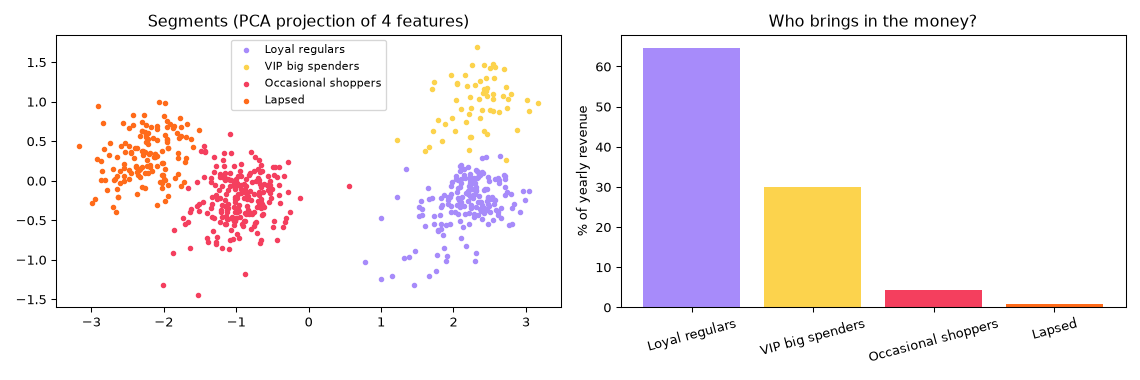

In [11]:
from IPython.display import Image, display
display(Image(filename='session-14_project_customer_segments.png'))  # chart saved by the cell above